# Hackathon IA — Clasificación de calidad de vino (Wine Quality)
**Métrica oficial:** F1-Score Macro · **Validación:** `StratifiedKFold` (5 folds, `shuffle=True`, `random_state=42`)

**Métodos permitidos:** distancias (Euclidiana, Manhattan, Minkowski, Coseno), k-means, k-NN, PCA, SVM (lineal, polinomial, RBF) y MLP.
No se usa ningún árbol, ensamble de árboles ni AutoML.

**Progresión del notebook**
1. EDA y limpieza
2. Baseline obligatorio: k-NN (k = 3, 5, 7 × Euclidiana / Manhattan) y k-means por mayoría
3. Feature engineering fisicoquímico + distancias a centroides k-means
4. PCA (varianza explicada, efecto en desempeño y tiempo)
5. SVM (lineal / polinomial / RBF) y MLP (red neuronal)
6. k-NN ponderado por distancia y ensamble *soft voting* de k-NN
7. Tabla comparativa, modelo final y `submission.csv`

Todo el preprocesamiento vive **dentro** de un `Pipeline`: el escalador, el PCA y el k-means se ajustan solo con el fold de entrenamiento → **cero data leakage**.

In [1]:
# === 0. Configuración del entorno (Google Colab o local) =====================
# En Colab: si los datos no están, pide subir hack_entrega.zip (o clona REPO_URL).
# En local: solo ubica la raíz del repositorio. No hay que tocar nada más.
import os, sys, glob, zipfile, subprocess
from pathlib import Path

REPO_URL = ""   # opcional, p. ej. "https://github.com/<usuario>/<repo>.git"
IN_COLAB = "google.colab" in sys.modules

def _find_root():
    for base in [Path.cwd(), Path.cwd().parent, Path("/content")]:
        hits = glob.glob(str(base / "**" / "data" / "train_public.csv"), recursive=True)
        if hits:
            return Path(hits[0]).resolve().parents[1]
    return None

if _find_root() is None and IN_COLAB:
    if REPO_URL:
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    else:
        from google.colab import files
        print("Sube el archivo hack_entrega.zip ...")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")

ROOT = _find_root()
assert ROOT is not None, "No encuentro data/train_public.csv: sube el zip o define REPO_URL"
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
print("Raíz del proyecto:", ROOT, "| Colab:", IN_COLAB)

Raíz del proyecto: /home/claude/hack | Colab: False


In [2]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier          # solo combina k-NN (no hay árboles)
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import f1_score, classification_report, confusion_matrix

from features import WineFeatures, KMeansDistances, BASE_FEATURES

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid", palette="deep")

train = pd.read_csv(ROOT / "data" / "train_public.csv")
test = pd.read_csv(ROOT / "data" / "test_public_features.csv")
X, y = train[BASE_FEATURES], train["target"].values
print("train:", train.shape, "| test:", test.shape)

train: (5197, 13) | test: (1300, 12)


## 1. Exploración de datos (EDA)

In [3]:
print("Valores faltantes  train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
print("Filas con features duplicadas en train:", train.duplicated(subset=BASE_FEATURES).sum())
dup_test = test.merge(train.drop_duplicates(BASE_FEATURES)[BASE_FEATURES], on=BASE_FEATURES, how="inner")
print("Filas del test idénticas a alguna de train:", len(dup_test), f"({len(dup_test)/len(test):.1%})")
print("\nDistribución de la clase objetivo:")
print(train["target"].value_counts().to_frame("n").assign(pct=lambda d: (d.n / d.n.sum()).round(3)))
train[BASE_FEATURES].describe().T.assign(skew=train[BASE_FEATURES].skew()).round(3)

Valores faltantes  train: 0 | test: 0
Filas con features duplicadas en train: 807
Filas del test idénticas a alguna de train: 337 (25.9%)

Distribución de la clase objetivo:
           n    pct
target             
0       4369  0.841
1        828  0.159


,count,mean,std,min,25%,50%,75%,max,skew
fixed_acidity,5197.0,7.220,1.299,3.900,6.400,7.000,7.700,15.600,1.683
volatile_acidity,5197.0,0.339,0.163,0.080,0.230,0.290,0.400,1.580,1.489
citric_acid,5197.0,0.319,0.144,0.000,0.250,0.310,0.390,1.660,0.466
residual_sugar,5197.0,5.474,4.789,0.600,1.800,3.100,8.100,65.800,1.497
chlorides,5197.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611,5.589
free_sulfur_dioxide,5197.0,30.461,17.560,1.000,17.000,29.000,41.000,289.000,1.224
total_sulfur_dioxide,5197.0,116.119,56.470,6.000,79.000,118.000,156.000,440.000,-0.024
density,5197.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039,0.615
pH,5197.0,3.217,0.160,2.720,3.110,3.210,3.320,4.010,0.343
sulphates,5197.0,0.532,0.151,0.220,0.430,0.510,0.600,2.000,1.907


**Lectura:** no hay nulos, pero sí **desbalance** (~84 % / ~16 %): por eso la métrica es F1-Macro, que pondera igual ambas clases (un modelo que diga siempre "0" tendría 84 % de accuracy y F1-Macro ≈ 0.46).
Hay muchas filas **repetidas** (807 en train) (en Wine Quality es normal: catas distintas con la misma analítica). Esto importa para los métodos basados en distancia: una muestra del test idéntica a una de train está a distancia 0 de su "gemela".
Las escalas son muy distintas (density ≈ 0.99 frente a total SO₂ hasta 440) y varias variables tienen **asimetría fuerte** (chlorides skew ≈ 5.6).

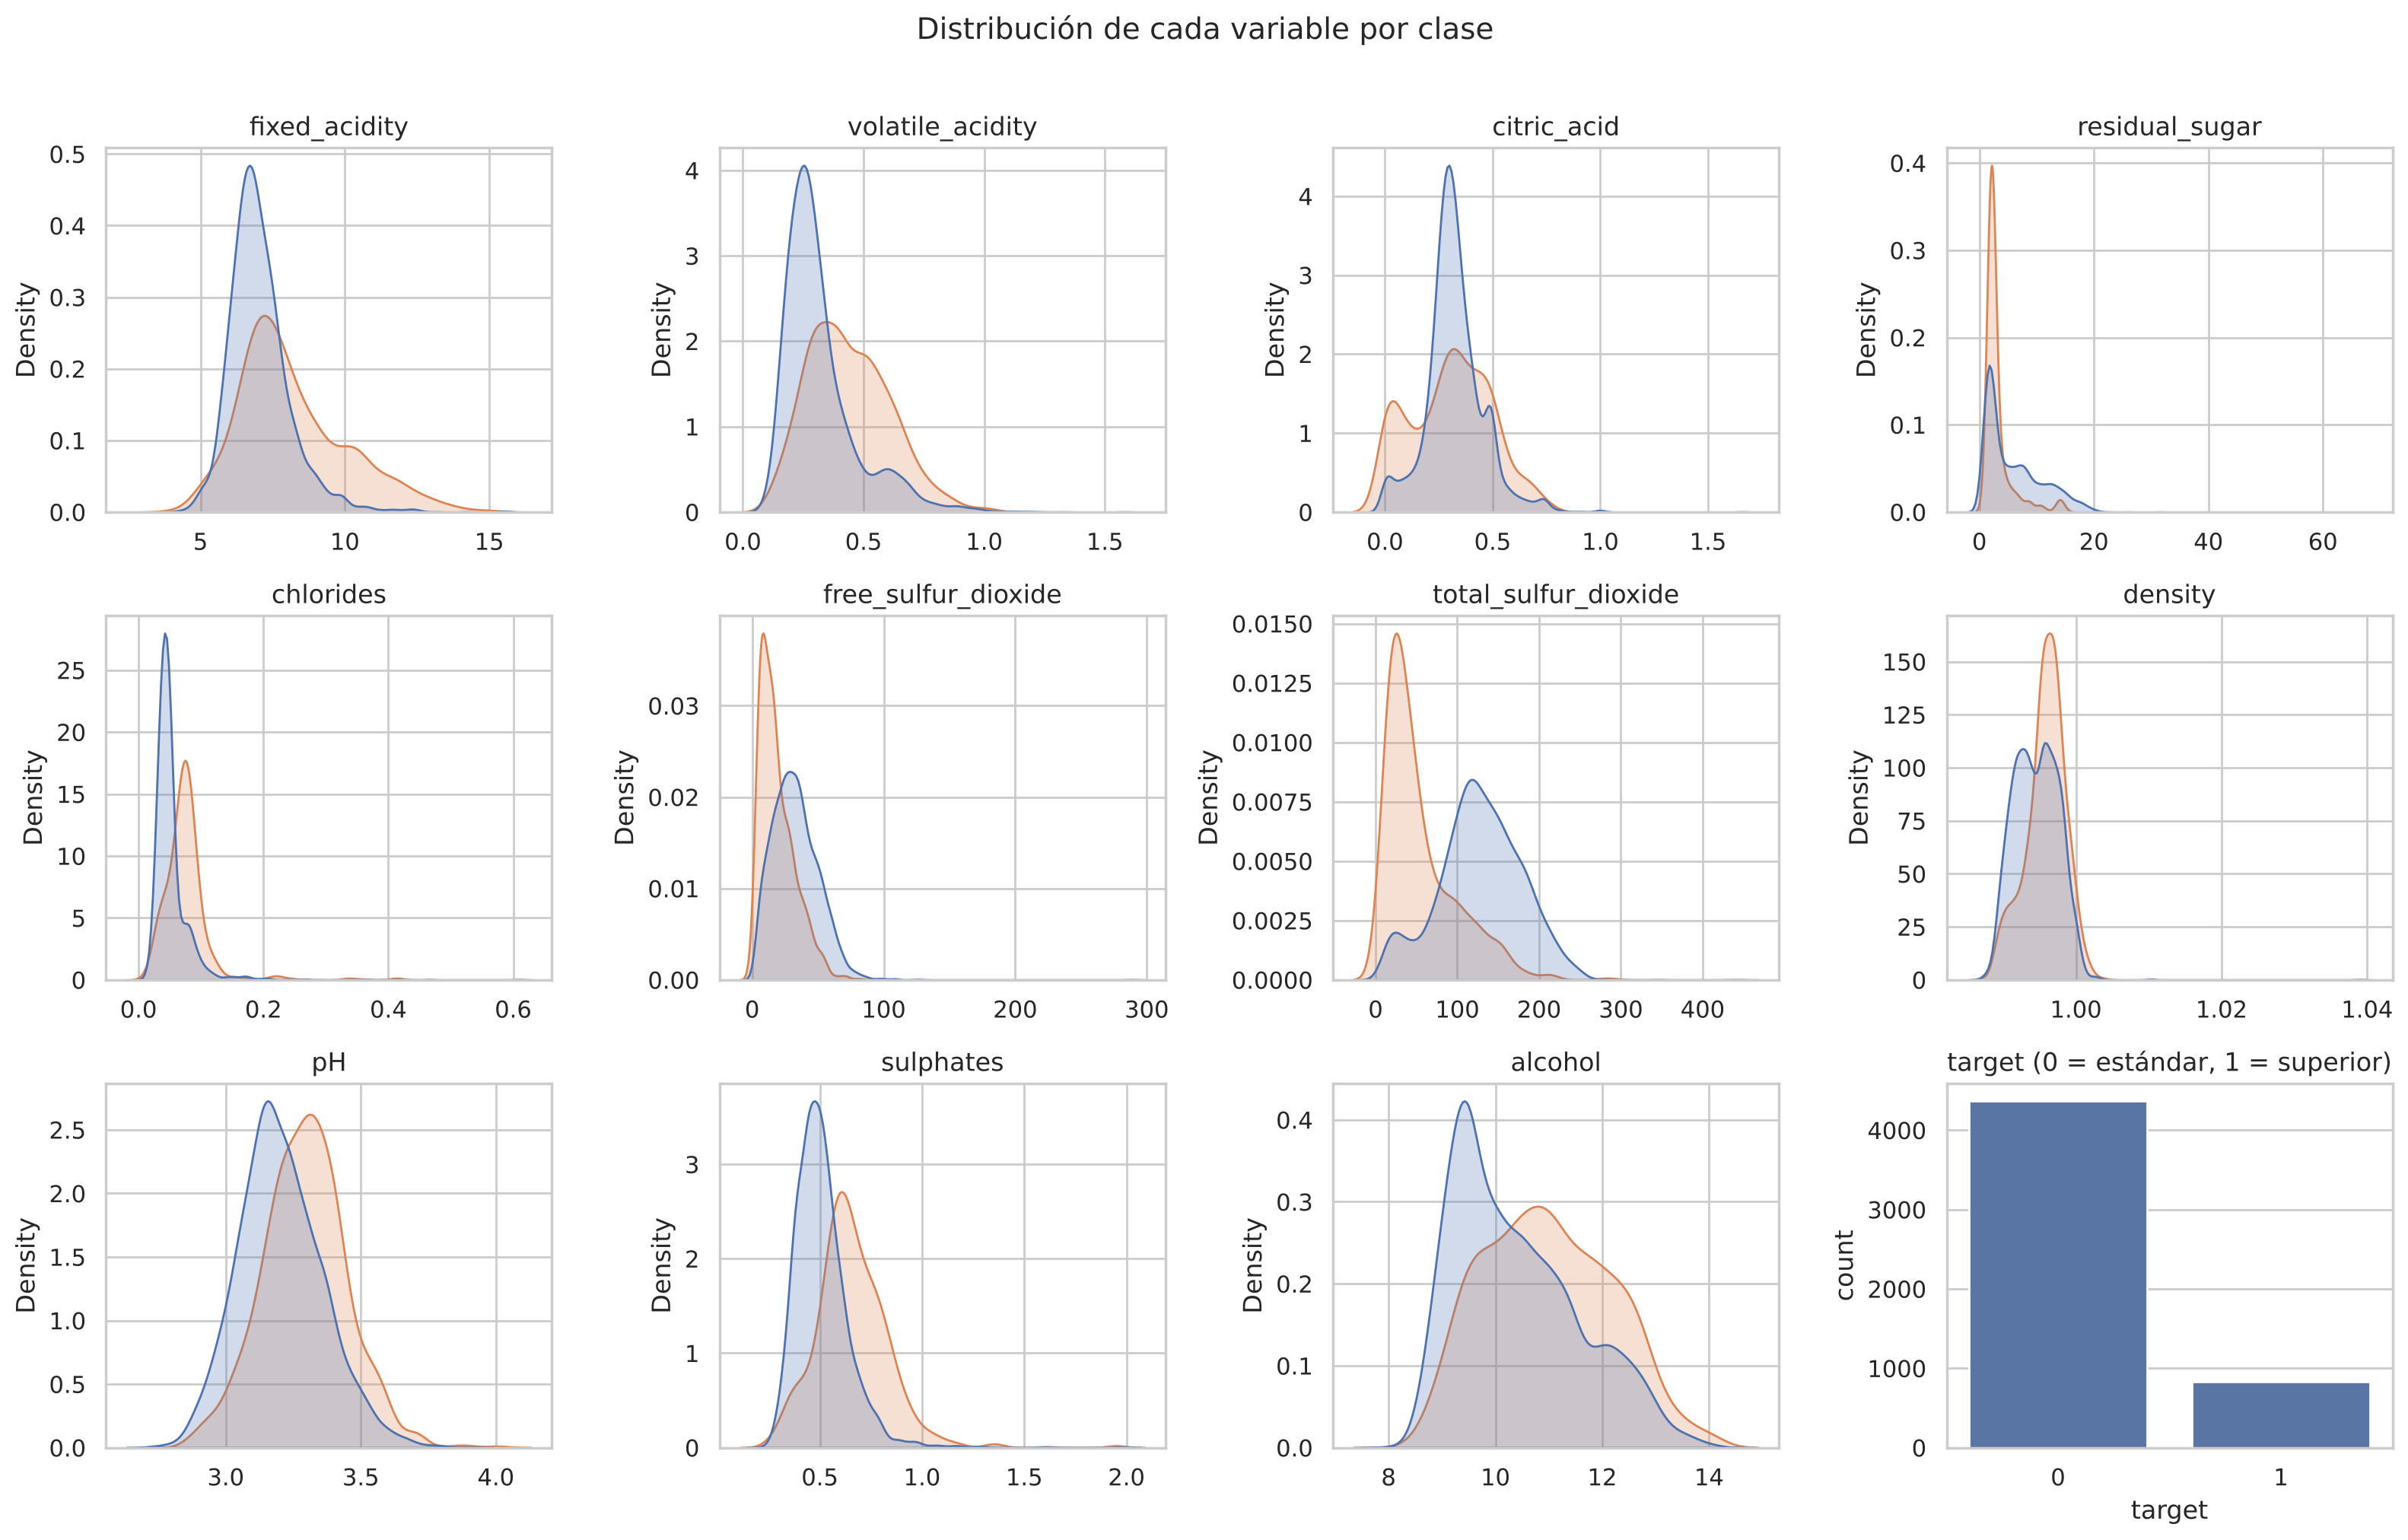

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), BASE_FEATURES):
    sns.kdeplot(data=train, x=col, hue="target", common_norm=False, fill=True, ax=ax, legend=False)
    ax.set_title(col); ax.set_xlabel("")
sns.countplot(data=train, x="target", ax=axes.ravel()[-1]); axes.ravel()[-1].set_title("target (0 = estándar, 1 = superior)")
plt.suptitle("Distribución de cada variable por clase", y=1.01, fontsize=14); plt.tight_layout(); plt.show()

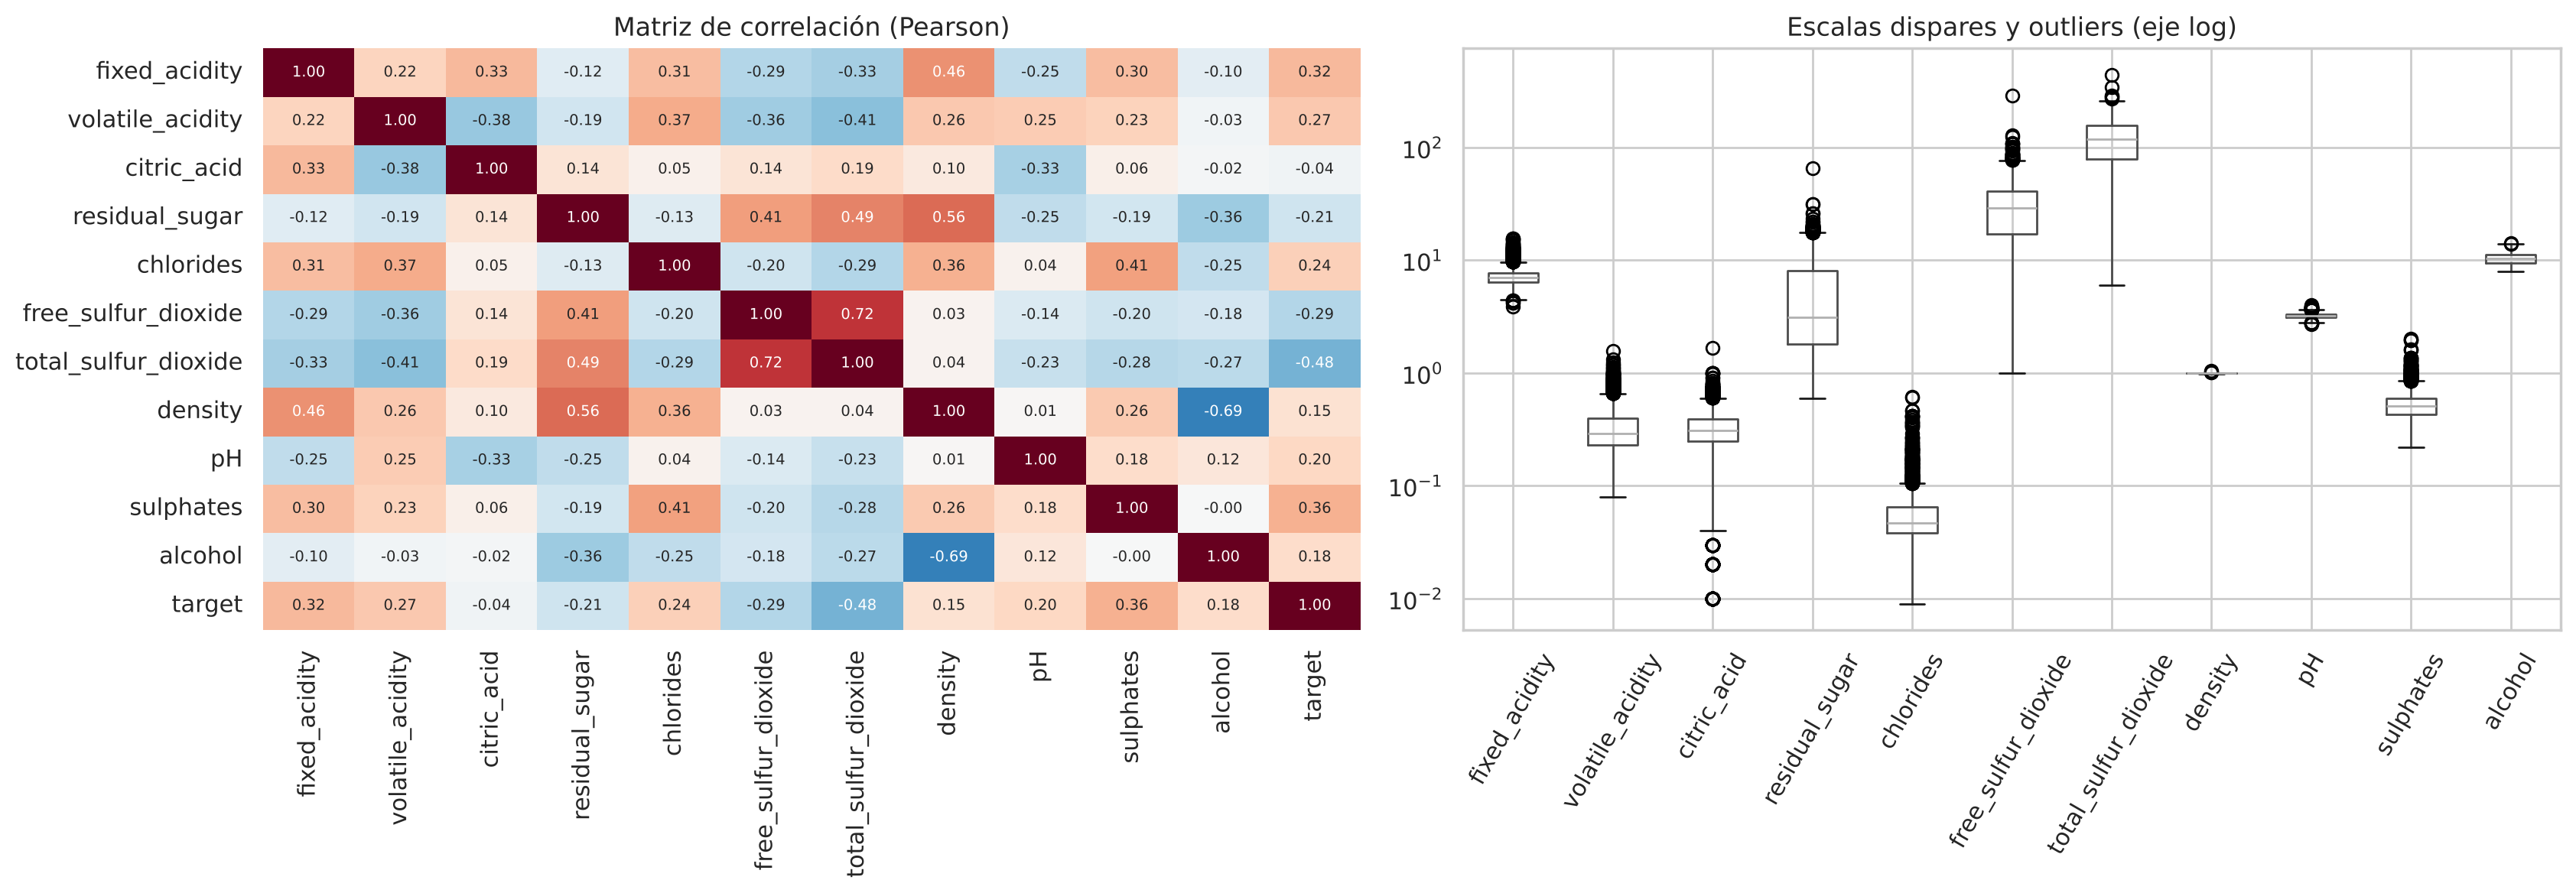

total_sulfur_dioxide   -0.476
free_sulfur_dioxide    -0.289
residual_sugar         -0.211
citric_acid            -0.043
density                 0.152
alcohol                 0.181
pH                      0.204
chlorides               0.241
volatile_acidity        0.269
fixed_acidity           0.323
sulphates               0.360
Name: target, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
corr = train[BASE_FEATURES + ["target"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar=False, annot_kws={"size": 7})
axes[0].set_title("Matriz de correlación (Pearson)")
train[BASE_FEATURES].boxplot(ax=axes[1], rot=60); axes[1].set_yscale("log")
axes[1].set_title("Escalas dispares y outliers (eje log)")
plt.tight_layout(); plt.show()
print(corr["target"].drop("target").sort_values().round(3))

**Por qué escalar.** La distancia Euclidiana es $d(x,z)=\sqrt{\sum_j (x_j-z_j)^2}$: si no escalamos, `total_sulfur_dioxide` (rango ~400) domina la suma y `density` (rango ~0.05) no aporta nada. Con `StandardScaler` cada variable queda con media 0 y varianza 1, y todas pesan lo mismo en la distancia.
En la MLP el escalado hace que la superficie de pérdida sea más "redonda": el gradiente no queda dominado por una sola dirección y Adam converge más rápido.
En el SVM-RBF, $K(x,z)=e^{-\gamma\|x-z\|^2}$ también depende de distancias, así que aplica lo mismo.

Correlaciones más fuertes con el target: `total_sulfur_dioxide` (−), `sulphates` (+), `fixed_acidity` (+). `free` y `total SO₂` están correlacionadas entre sí (≈0.72) y `density` con `alcohol` / `residual_sugar`: hay redundancia que PCA puede comprimir.

## 2. Baseline obligatorio: k-NN y k-means

In [6]:
results = []   # tabla comparativa global

def evaluate(name, model, family, X_=X):
    cv = cross_validate(model, X_, y, cv=CV, scoring="f1_macro", n_jobs=-1)
    row = dict(modelo=name, familia=family,
               f1_macro=cv["test_score"].mean(), f1_std=cv["test_score"].std(),
               fit_time_s=cv["fit_time"].mean(), pred_time_s=cv["score_time"].mean())
    results.append(row)
    print(f"{name:55s} F1-Macro = {row['f1_macro']:.4f} ± {row['f1_std']:.4f}   fit {row['fit_time_s']:.2f}s")
    return row

for k in [3, 5, 7]:
    for metric, p in [("Euclidiana", 2), ("Manhattan", 1)]:
        evaluate(f"k-NN k={k} {metric}",
                 Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k, p=p))]),
                 "Baseline k-NN")

k-NN k=3 Euclidiana                                     F1-Macro = 0.8034 ± 0.0146   fit 0.02s
k-NN k=3 Manhattan                                      F1-Macro = 0.8066 ± 0.0165   fit 0.01s


k-NN k=5 Euclidiana                                     F1-Macro = 0.7998 ± 0.0117   fit 0.01s


k-NN k=5 Manhattan                                      F1-Macro = 0.7987 ± 0.0179   fit 0.01s
k-NN k=7 Euclidiana                                     F1-Macro = 0.8008 ± 0.0051   fit 0.01s


k-NN k=7 Manhattan                                      F1-Macro = 0.7985 ± 0.0154   fit 0.01s


In [7]:
class KMeansMajority(BaseEstimator, ClassifierMixin):
    # Clasificador k-means: cada clúster predice la clase mayoritaria (o la proporción de clase 1)
    # de las muestras de entrenamiento que cayeron en él.
    def __init__(self, n_clusters=20, threshold=0.5, random_state=42):
        self.n_clusters, self.threshold, self.random_state = n_clusters, threshold, random_state
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.km_ = KMeans(self.n_clusters, n_init=10, random_state=self.random_state).fit(X)
        lab = self.km_.labels_
        self.rate_ = np.array([y[lab == c].mean() if (lab == c).any() else 0 for c in range(self.n_clusters)])
        return self
    def predict_proba(self, X):
        p = self.rate_[self.km_.predict(X)]; return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

for k in [10, 30, 60]:
    for th in [0.5, 0.3]:
        evaluate(f"k-means (k={k}) mayoría, umbral {th}",
                 Pipeline([("sc", StandardScaler()), ("km", KMeansMajority(k, th))]), "Baseline k-means")

k-means (k=10) mayoría, umbral 0.5                      F1-Macro = 0.6876 ± 0.0545   fit 0.08s


k-means (k=10) mayoría, umbral 0.3                      F1-Macro = 0.7671 ± 0.0156   fit 0.09s


k-means (k=30) mayoría, umbral 0.5                      F1-Macro = 0.7581 ± 0.0164   fit 0.16s


k-means (k=30) mayoría, umbral 0.3                      F1-Macro = 0.7783 ± 0.0127   fit 0.19s


k-means (k=60) mayoría, umbral 0.5                      F1-Macro = 0.7811 ± 0.0035   fit 0.30s


k-means (k=60) mayoría, umbral 0.3                      F1-Macro = 0.7954 ± 0.0120   fit 0.33s


**Baseline de referencia:** k-NN estandarizado con Euclidiana/Manhattan da F1-Macro ≈ 0.80–0.81. Manhattan ($L_1$) es un poco más robusta a outliers porque no eleva al cuadrado las diferencias.
k-means por mayoría queda por debajo: los clústeres se forman sin mirar la etiqueta (no supervisado), así que mezclan ambas clases. Bajar el umbral a 0.3 ayuda porque la clase 1 es minoritaria y casi nunca es mayoría absoluta en un clúster.

## 3. Feature engineering fisicoquímico y geométrico

,corr con target
acid_ratio,-0.136
free_so2_ratio,0.374
alcohol_density,0.173
sugar_alcohol,-0.218
bound_so2,-0.480
total_acidity,0.329


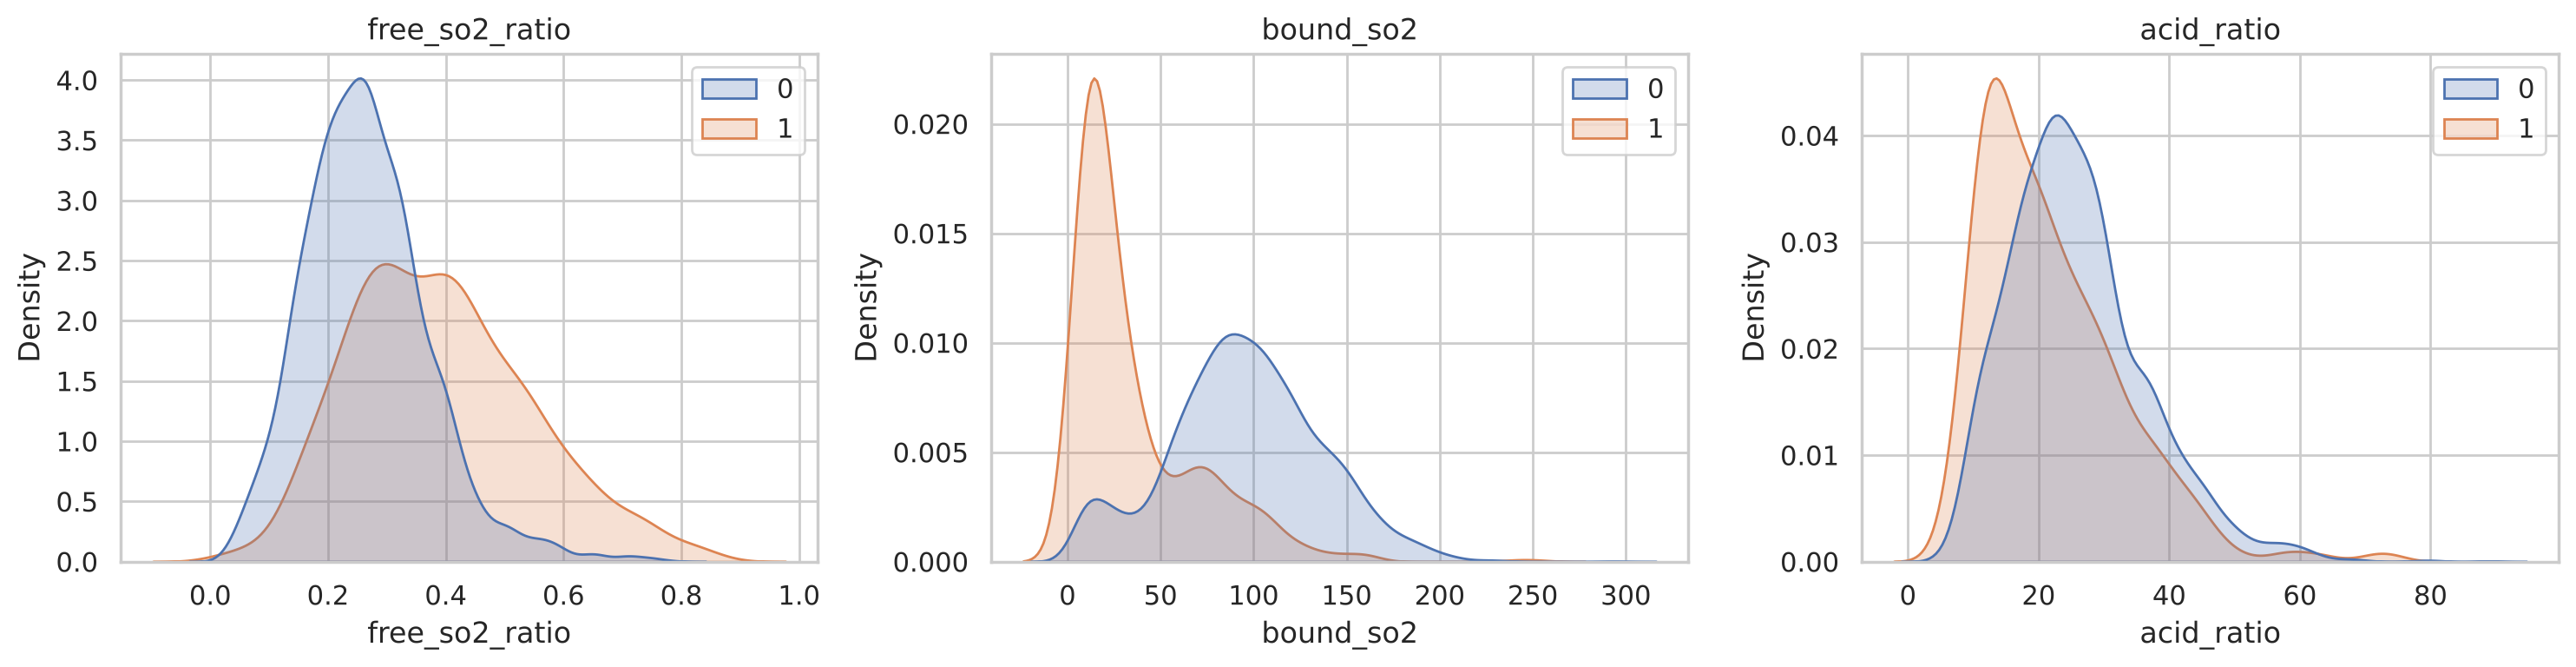

In [8]:
fe = WineFeatures(log_transform=False).fit(X)
Xfe = pd.DataFrame(fe.transform(X), columns=fe.get_feature_names_out())
new_cols = ["acid_ratio", "free_so2_ratio", "alcohol_density", "sugar_alcohol", "bound_so2", "total_acidity"]
display(Xfe[new_cols].assign(target=y).corr()["target"].drop("target").round(3).to_frame("corr con target"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["free_so2_ratio", "bound_so2", "acid_ratio"]):
    sns.kdeplot(x=Xfe[c], hue=y, common_norm=False, fill=True, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

Variables nuevas (implementadas en `src/features.py`, todas dentro del Pipeline):

| Variable | Fórmula | Sentido fisicoquímico |
|---|---|---|
| `acid_ratio` | fixed / volatile | acidez "estructural" frente a acidez avinagrada |
| `free_so2_ratio` | free SO₂ / total SO₂ | fracción del SO₂ que realmente protege el vino |
| `alcohol_density` | alcohol / density | grado alcohólico relativo al cuerpo |
| `sugar_alcohol` | residual sugar / alcohol | dulzor relativo (fermentación incompleta) |
| `bound_so2` | total − free SO₂ | SO₂ ligado (inactivo) |
| `total_acidity` | fixed + volatile + citric | acidez total |
| `dist_centroide_j` | $\|x-\mu_j\|_2$, j = 1..k | **geométrica**: posición de la muestra respecto a los centroides k-means |

Además, `log1p` a las variables con skew > 1, para que la distancia no la dominen los outliers.

In [9]:
for name, steps in {
    "k-NN k=7 Manhattan + FE (ratios + log)": [("fe", WineFeatures()), ("sc", StandardScaler()),
                                                ("knn", KNeighborsClassifier(7, p=1))],
    "k-NN k=7 Manhattan + FE + dist. k-means(8)": [("fe", WineFeatures()), ("sc", StandardScaler()),
                                                   ("km", KMeansDistances(8)), ("knn", KNeighborsClassifier(7, p=1))],
}.items():
    evaluate(name, Pipeline(steps), "Feature Engineering")

k-NN k=7 Manhattan + FE (ratios + log)                  F1-Macro = 0.7886 ± 0.0103   fit 0.02s


k-NN k=7 Manhattan + FE + dist. k-means(8)              F1-Macro = 0.7939 ± 0.0098   fit 0.09s


## 4. PCA — reducción de dimensionalidad

Componentes para 90 % de varianza: 8 | para 95 %: 9 (de 17 variables)


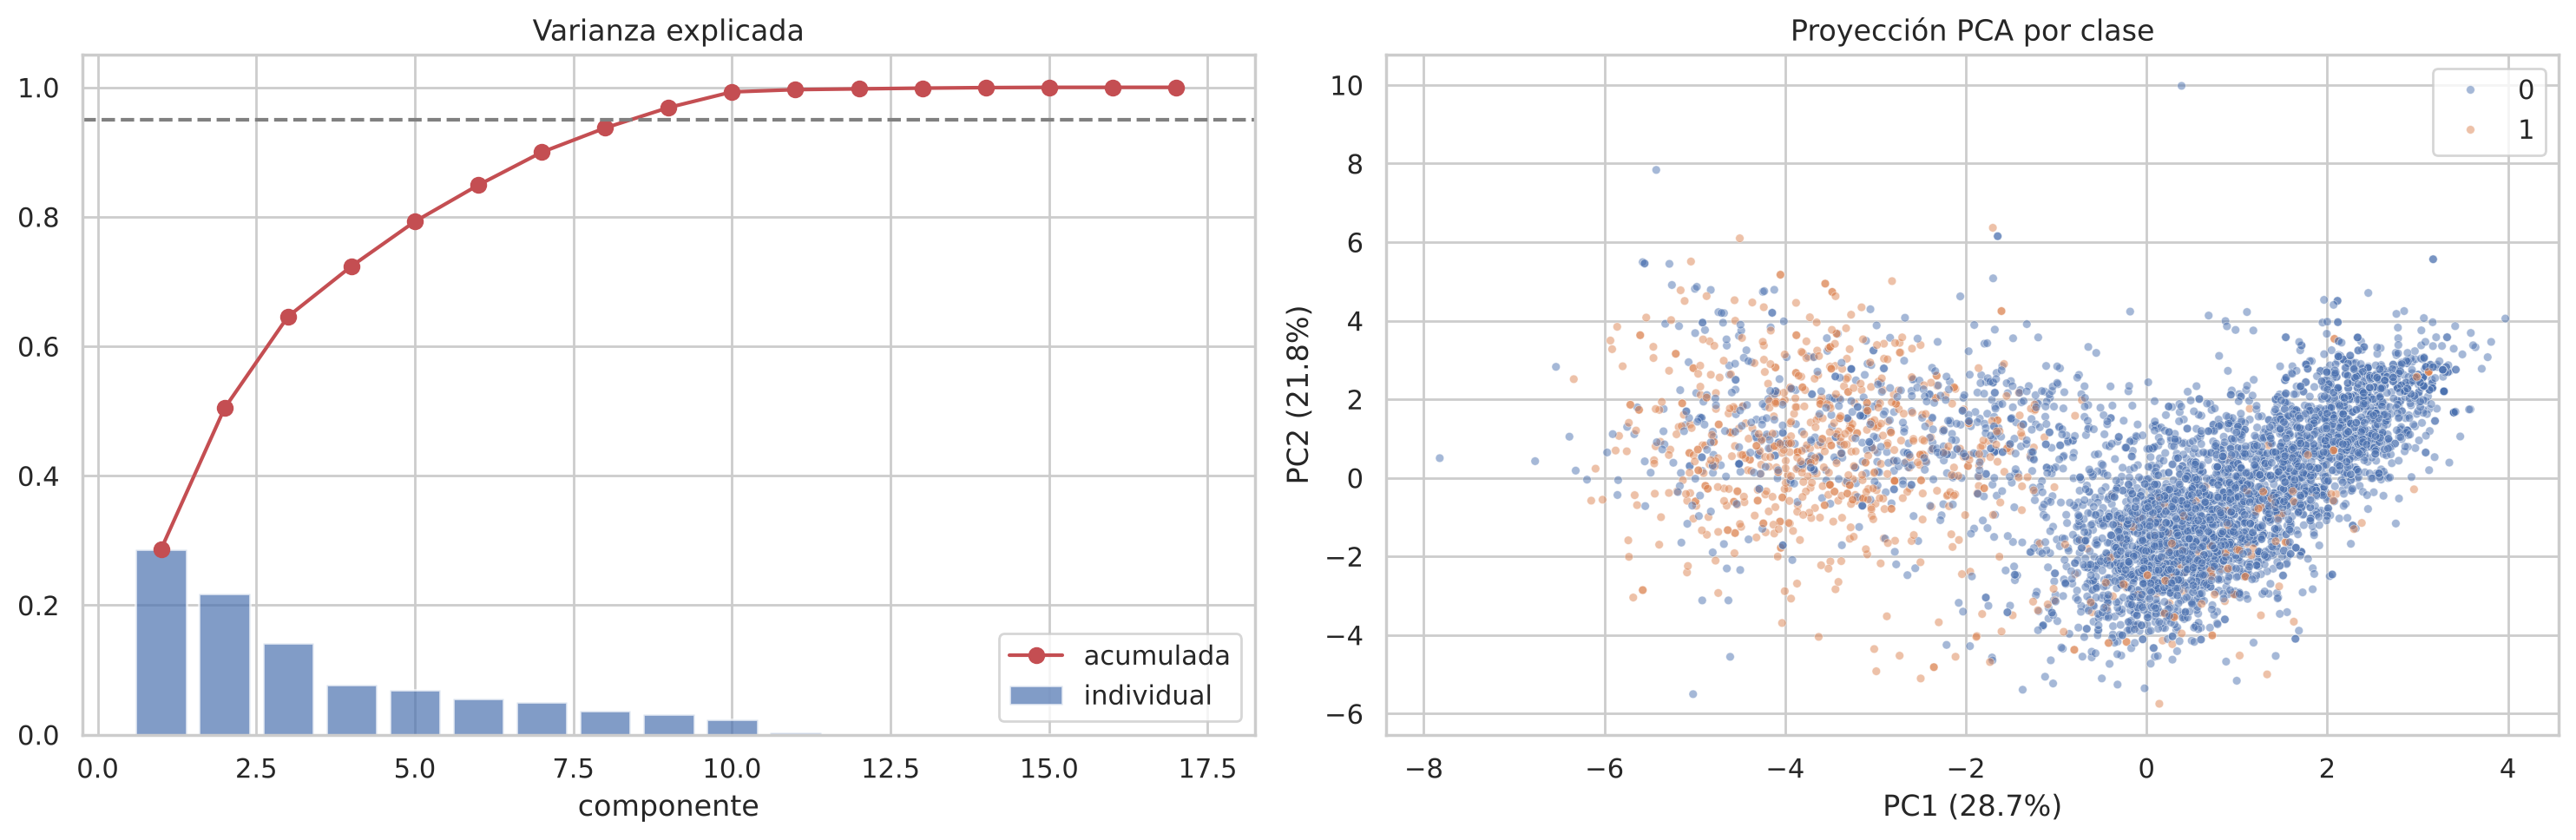

,volatile_acidity,total_acidity,sulphates,chlorides,fixed_acidity,free_so2_ratio,pH,alcohol,alcohol_density,density,citric_acid,acid_ratio,residual_sugar,sugar_alcohol,free_sulfur_dioxide,bound_so2,total_sulfur_dioxide
PC1,-0.3,-0.22,-0.22,-0.21,-0.2,-0.18,-0.15,-0.11,-0.11,-0.02,0.10,0.21,0.28,0.29,0.33,0.40,0.41
PC2,0.1,0.30,0.13,0.24,0.3,0.02,-0.13,-0.40,-0.41,0.48,0.13,0.01,0.25,0.28,-0.01,-0.03,-0.03


In [10]:
pipe_pca = Pipeline([("fe", WineFeatures()), ("sc", StandardScaler()), ("pca", PCA())]).fit(X)
evr = pipe_pca["pca"].explained_variance_ratio_
cum = np.cumsum(evr)
n90, n95 = np.argmax(cum >= 0.90) + 1, np.argmax(cum >= 0.95) + 1
print(f"Componentes para 90 % de varianza: {n90} | para 95 %: {n95} (de {len(evr)} variables)")

Z = pipe_pca.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(1, len(evr) + 1), evr, alpha=.7, label="individual")
axes[0].plot(range(1, len(evr) + 1), cum, "o-", color="C3", label="acumulada")
axes[0].axhline(.95, ls="--", c="gray"); axes[0].set_xlabel("componente"); axes[0].set_title("Varianza explicada"); axes[0].legend()
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, alpha=.5, s=12, ax=axes[1])
axes[1].set_xlabel(f"PC1 ({evr[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({evr[1]:.1%})"); axes[1].set_title("Proyección PCA por clase")
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pipe_pca["pca"].components_[:2].T, index=pipe_pca["fe"].get_feature_names_out(), columns=["PC1", "PC2"])
loadings.sort_values("PC1").round(2).T

PCA busca las direcciones de máxima varianza: los autovectores de la matriz de covarianza $\Sigma = \frac{1}{n}X^\top X$ (con $X$ estandarizada). PC1 separa claramente dos grupos: por los *loadings* (SO₂ y azúcar en un extremo; acidez fija, sulfatos y cloruros en el otro) corresponden a la firma química de **vino blanco frente a tinto**, y la clase 1 se concentra en uno de ellos.

In [11]:
for var in [0.90, 0.95]:
    evaluate(f"PCA {int(var*100)}% + k-NN k=7 Manhattan",
             Pipeline([("fe", WineFeatures()), ("sc", StandardScaler()), ("pca", PCA(var)),
                       ("knn", KNeighborsClassifier(7, p=1))]), "PCA")
    evaluate(f"PCA {int(var*100)}% + SVM RBF (C=3, γ=0.3)",
             Pipeline([("fe", WineFeatures()), ("sc", StandardScaler()), ("pca", PCA(var)),
                       ("svm", SVC(C=3, gamma=0.3))]), "PCA")

PCA 90% + k-NN k=7 Manhattan                            F1-Macro = 0.7910 ± 0.0083   fit 0.02s


PCA 90% + SVM RBF (C=3, γ=0.3)                          F1-Macro = 0.8018 ± 0.0123   fit 0.22s


PCA 95% + k-NN k=7 Manhattan                            F1-Macro = 0.8033 ± 0.0111   fit 0.02s


PCA 95% + SVM RBF (C=3, γ=0.3)                          F1-Macro = 0.8078 ± 0.0101   fit 0.27s


**Conclusión PCA:** con 95 % de varianza la dimensión baja de 17 a 9.
- En **k-NN**, PCA 95 % *mejora* frente a usar las 17 variables FE sin comprimir (≈0.789 → ≈0.803): las features nuevas son redundantes entre sí (ratios de las mismas variables) e "inflan" la distancia en ciertas direcciones. PCA las decorrelaciona y quita dimensiones de ruido.
- En **SVM RBF**, PCA *empeora* frente al SVM sobre las variables originales (≈0.817 → ≈0.808). PCA no es supervisado: descarta direcciones de poca varianza que sí discriminan la clase.
- Quedarse con 90 % es peor que con 95 %: se pierde demasiada información.

Por eso el modelo final no usa PCA. Sí lo usamos para visualizar y entender la estructura de los datos.

## 5. Modelos avanzados: SVM y MLP

In [12]:
t0 = time.time()
svm_pipe = Pipeline([("sc", StandardScaler()), ("svm", SVC())])
svm_grid = GridSearchCV(svm_pipe, [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10], "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["poly"], "svm__degree": [2, 3], "svm__C": [1, 10], "svm__gamma": ["scale"], "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"], "svm__C": [1, 3, 10, 30], "svm__gamma": ["scale", 0.3, 1.0], "svm__class_weight": [None, "balanced"]},
], cv=CV, scoring="f1_macro", n_jobs=-1).fit(X, y)
print(f"GridSearch SVM: {time.time()-t0:.1f}s | mejor: {svm_grid.best_params_} -> {svm_grid.best_score_:.4f}")

svm_res = pd.DataFrame(svm_grid.cv_results_)
best_by_kernel = svm_res.loc[svm_res.groupby("param_svm__kernel")["mean_test_score"].idxmax()]
for _, r in best_by_kernel.iterrows():
    results.append(dict(modelo=f"SVM {r['param_svm__kernel']} (mejor del grid)", familia="SVM",
                        f1_macro=r["mean_test_score"], f1_std=r["std_test_score"],
                        fit_time_s=r["mean_fit_time"], pred_time_s=r["mean_score_time"]))
best_by_kernel[["param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__class_weight", "mean_test_score", "std_test_score"]]

GridSearch SVM: 42.3s | mejor: {'svm__C': 3, 'svm__class_weight': None, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'} -> 0.8170


,param_svm__kernel,param_svm__C,param_svm__gamma,param_svm__class_weight,mean_test_score,std_test_score
2,linear,1.0,NaN,NaN,0.806819,0.010445
11,poly,10.0,scale,NaN,0.790299,0.016267
20,rbf,3.0,scale,NaN,0.816960,0.013966


El SVM busca el hiperplano de **margen máximo** $\min \frac12\|w\|^2 + C\sum\xi_i$. El kernel lineal no alcanza: la frontera entre clases no es lineal. RBF es el mejor kernel; $\gamma$ controla el radio de influencia de cada vector de soporte ($\gamma$ alto → frontera muy local, sobreajuste) y $C$ el costo de violar el margen.

In [13]:
t0 = time.time()
mlp_pipe = Pipeline([("fe", WineFeatures()), ("sc", StandardScaler()),
                     ("mlp", MLPClassifier(max_iter=1500, random_state=SEED))])
mlp_grid = GridSearchCV(mlp_pipe, {
    "mlp__hidden_layer_sizes": [(32,), (64, 32), (128, 128)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [1e-4, 1e-2],
}, cv=CV, scoring="f1_macro", n_jobs=-1).fit(X, y)
print(f"GridSearch MLP: {time.time()-t0:.1f}s | mejor: {mlp_grid.best_params_} -> {mlp_grid.best_score_:.4f}")

mlp_res = pd.DataFrame(mlp_grid.cv_results_).sort_values("mean_test_score", ascending=False)
for _, r in mlp_res.head(3).iterrows():
    results.append(dict(modelo=f"MLP {r['param_mlp__hidden_layer_sizes']} {r['param_mlp__activation']} α={r['param_mlp__alpha']}",
                        familia="MLP (Red Neuronal)", f1_macro=r["mean_test_score"], f1_std=r["std_test_score"],
                        fit_time_s=r["mean_fit_time"], pred_time_s=r["mean_score_time"]))
mlp_res[["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__alpha", "mean_test_score", "std_test_score", "mean_fit_time"]].head(8)

GridSearch MLP: 215.1s | mejor: {'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128, 128)} -> 0.8310


,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__alpha,mean_test_score,std_test_score,mean_fit_time
8,"(128, 128)",tanh,0.0001,0.831012,0.020460,11.900751
11,"(128, 128)",tanh,0.0100,0.830366,0.019733,14.455594
5,"(128, 128)",relu,0.0100,0.820759,0.024136,7.545035
2,"(128, 128)",relu,0.0001,0.820036,0.015652,7.757093
7,"(64, 32)",tanh,0.0001,0.816406,0.018633,7.852404
10,"(64, 32)",tanh,0.0100,0.816096,0.021052,7.223474
1,"(64, 32)",relu,0.0001,0.813463,0.014346,4.481581
4,"(64, 32)",relu,0.0100,0.812283,0.020358,3.939868


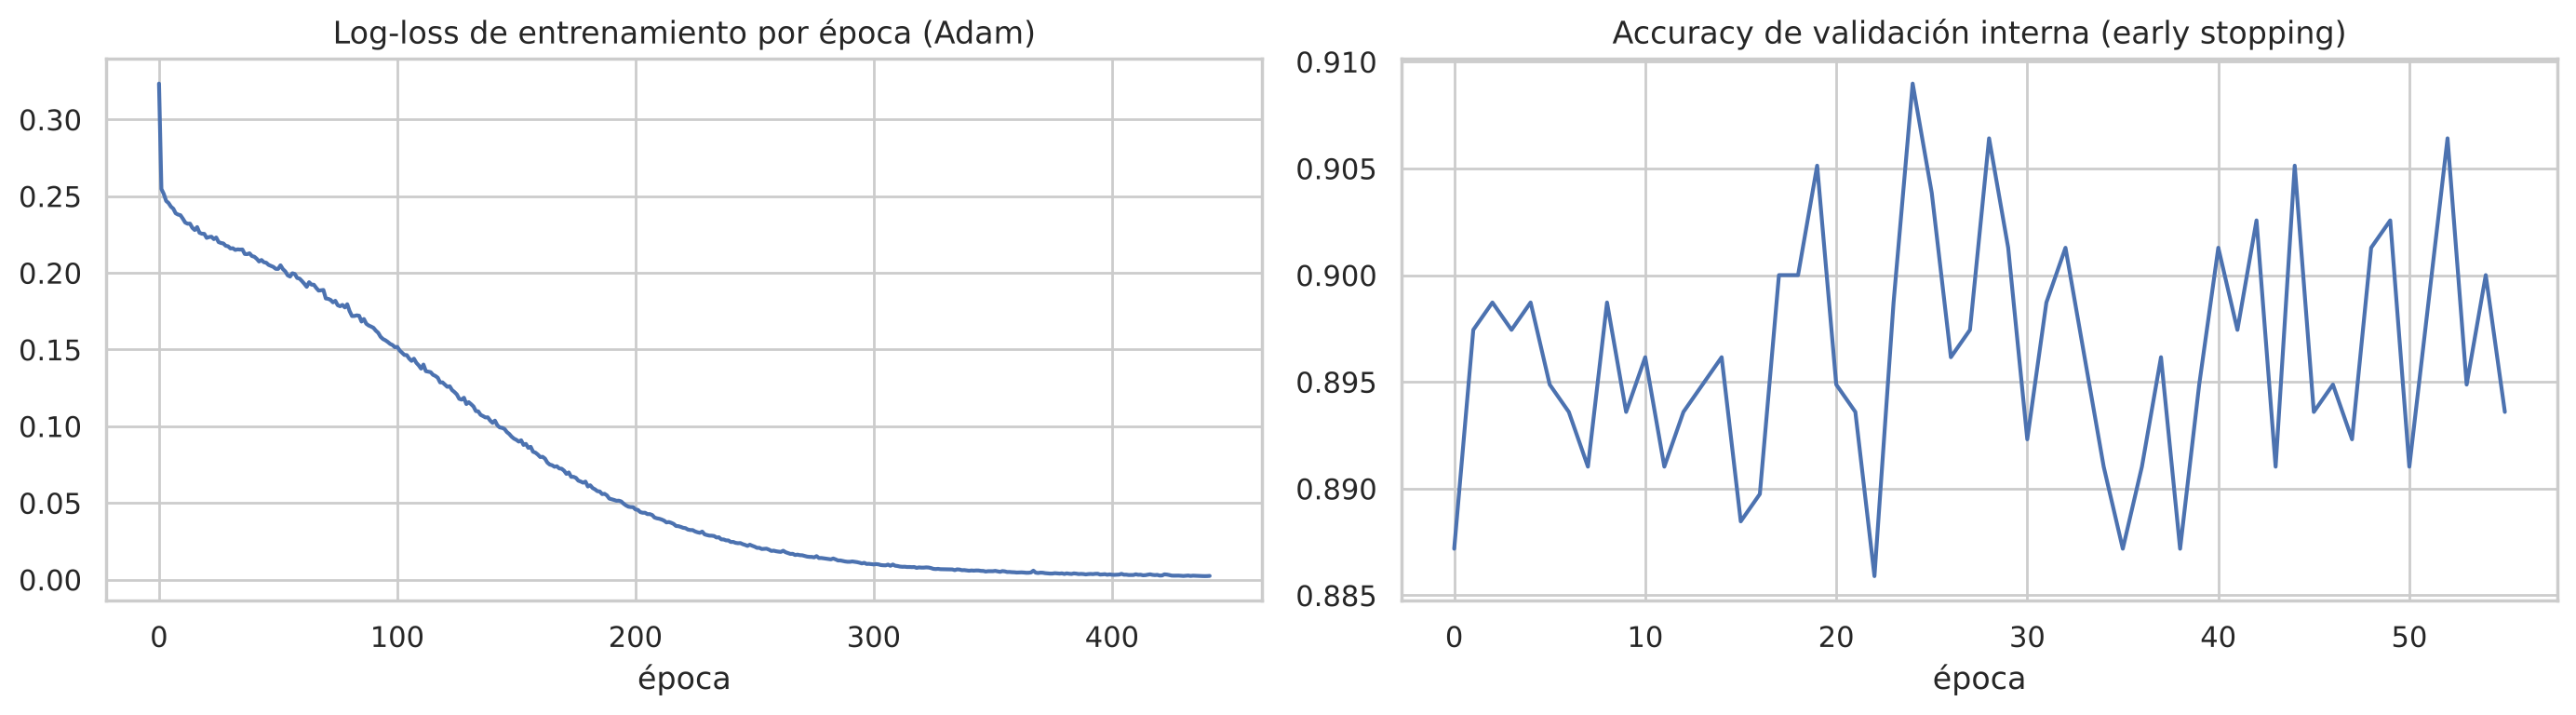

MLP mejor config + early stopping                       F1-Macro = 0.8052 ± 0.0139   fit 1.16s


{'modelo': 'MLP mejor config + early stopping',
 'familia': 'MLP (Red Neuronal)',
 'f1_macro': np.float64(0.8051799063338244),
 'f1_std': np.float64(0.01393502649479922),
 'fit_time_s': np.float64(1.1592199325561523),
 'pred_time_s': np.float64(0.010884952545166016)}

In [14]:
# Curva de aprendizaje de la mejor MLP + early stopping como regularización adicional
best_mlp = clone(mlp_grid.best_estimator_).fit(X, y)
es_mlp = clone(mlp_grid.best_estimator_).set_params(mlp__early_stopping=True, mlp__validation_fraction=0.15,
                                                     mlp__n_iter_no_change=30).fit(X, y)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(best_mlp["mlp"].loss_curve_); ax[0].set_title("Log-loss de entrenamiento por época (Adam)"); ax[0].set_xlabel("época")
ax[1].plot(es_mlp["mlp"].validation_scores_); ax[1].set_title("Accuracy de validación interna (early stopping)"); ax[1].set_xlabel("época")
plt.tight_layout(); plt.show()
evaluate("MLP mejor config + early stopping", clone(es_mlp), "MLP (Red Neuronal)")

**La red neuronal.** Cada neurona calcula $a = \sigma(w^\top x + b)$. Con capas ocultas ReLU/tanh la MLP es un aproximador universal. Se entrena con *forward pass* → log-loss → *backpropagation* (regla de la cadena) → actualización con Adam. La regularización L2 (`alpha`, *weight decay*) penaliza $\alpha\|W\|^2$; el *early stopping* corta el entrenamiento cuando la validación interna deja de mejorar.
La mejor MLP (2 capas ocultas de 128 neuronas, `tanh`, α = 1e-4) supera a los baselines k-NN y al SVM (F1 ≈ 0.83), pero tiene la mayor varianza entre folds (±0.02) y es el modelo más costoso de entrenar (~12 s por fold frente a ~0.01 s del k-NN).
El *early stopping* empeoró el resultado (≈0.805): reserva 15 % de los datos para validación, así que la red entrena con menos ejemplos de la clase minoritaria. La regularización L2 sola funcionó mejor.

## 6. k-NN ponderado por distancia: aprovechar la geometría local

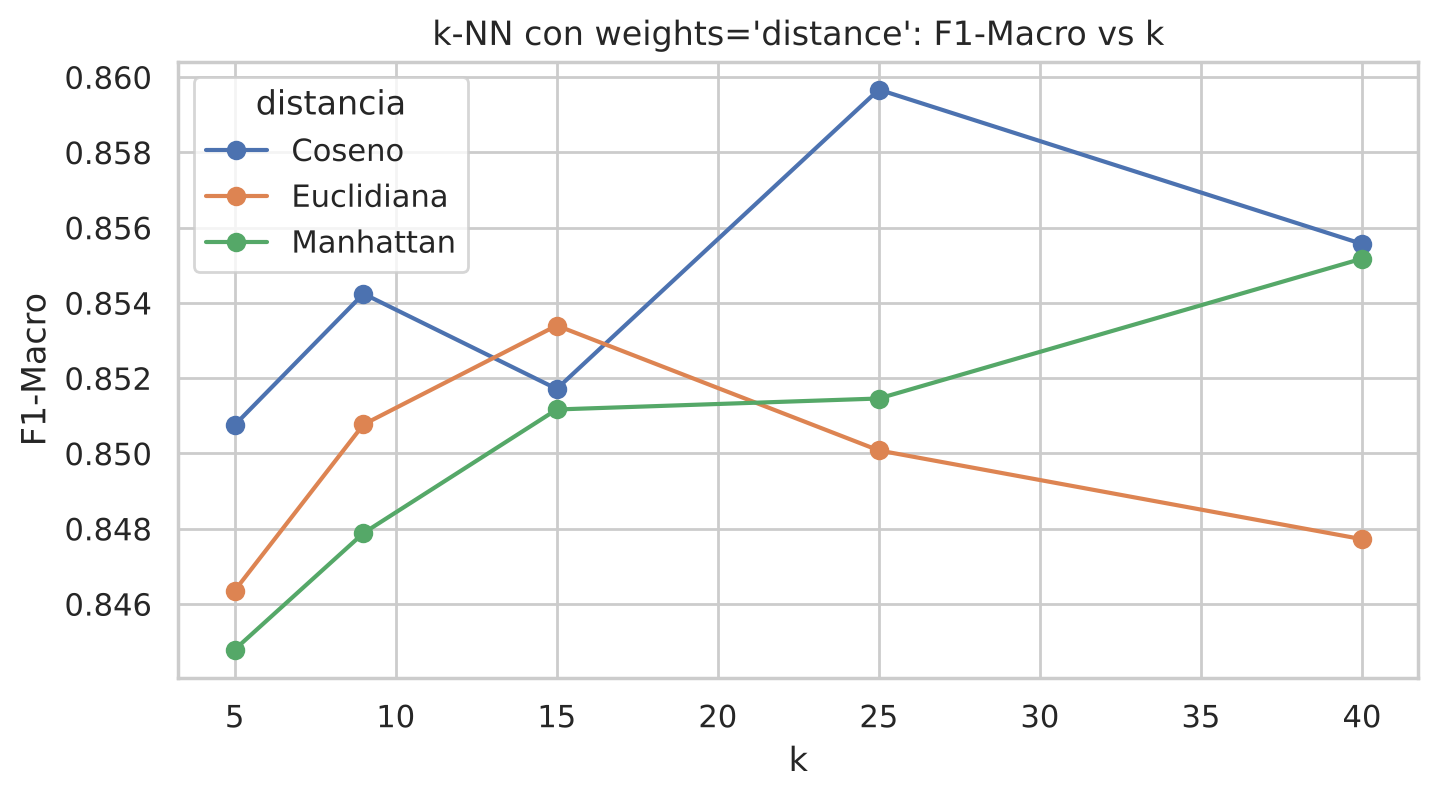

distancia,Coseno,Euclidiana,Manhattan
k,,,
5,0.8508,0.8464,0.8448
9,0.8542,0.8508,0.8479
15,0.8517,0.8534,0.8512
25,0.8597,0.8501,0.8515
40,0.8556,0.8477,0.8552


In [15]:
rows = []
for k in [5, 9, 15, 25, 40]:
    for name, kw in [("Manhattan", dict(p=1)), ("Euclidiana", dict(p=2)),
                     ("Coseno", dict(metric="cosine", algorithm="brute"))]:
        s = cross_validate(Pipeline([("sc", StandardScaler()),
                                     ("knn", KNeighborsClassifier(k, weights="distance", **kw))]),
                           X, y, cv=CV, scoring="f1_macro", n_jobs=-1)["test_score"]
        rows.append(dict(k=k, distancia=name, f1=s.mean()))
grid_knn = pd.DataFrame(rows).pivot(index="k", columns="distancia", values="f1")
ax = grid_knn.plot(marker="o", figsize=(8, 4), title="k-NN con weights='distance': F1-Macro vs k"); ax.set_ylabel("F1-Macro"); plt.show()
grid_knn.round(4)

Con `weights="distance"` cada vecino vota con peso $w_i = 1/d(x, x_i)$. Si un vecino está a distancia 0 (muestra repetida), su voto es el único que cuenta. Esto es potente aquí porque **≈26 % del test tiene una gemela exacta en train**, y muchas otras muestras tienen casi-gemelas.
Además, con pesos por distancia podemos usar un $k$ grande (vecindario estable, menos varianza) sin perder la información local: es un *trade-off* sesgo–varianza muy favorable.

In [16]:
knn_specs = {
    "knn_manhattan_k40": Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(40, p=1, weights="distance"))]),
    "knn_coseno_k15":    Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(15, metric="cosine", algorithm="brute", weights="distance"))]),
    "knn_FE_manhattan_k25": Pipeline([("fe", WineFeatures()), ("sc", StandardScaler()), ("knn", KNeighborsClassifier(25, p=1, weights="distance"))]),
}
evaluate("k-NN k=40 Manhattan, peso 1/d", knn_specs["knn_manhattan_k40"], "k-NN ponderado")
evaluate("k-NN k=15 Coseno, peso 1/d", knn_specs["knn_coseno_k15"], "k-NN ponderado")
evaluate("k-NN k=25 Manhattan + FE, peso 1/d", knn_specs["knn_FE_manhattan_k25"], "k-NN ponderado")

ensemble = VotingClassifier(list(knn_specs.items()), voting="soft")
evaluate("ENSAMBLE soft-voting de 3 k-NN (Manhattan + Coseno + FE)", ensemble, "Ensamble k-NN")

k-NN k=40 Manhattan, peso 1/d                           F1-Macro = 0.8552 ± 0.0092   fit 0.01s
k-NN k=15 Coseno, peso 1/d                              F1-Macro = 0.8517 ± 0.0172   fit 0.01s


k-NN k=25 Manhattan + FE, peso 1/d                      F1-Macro = 0.8527 ± 0.0115   fit 0.01s


ENSAMBLE soft-voting de 3 k-NN (Manhattan + Coseno + FE) F1-Macro = 0.8599 ± 0.0077   fit 0.02s


{'modelo': 'ENSAMBLE soft-voting de 3 k-NN (Manhattan + Coseno + FE)',
 'familia': 'Ensamble k-NN',
 'f1_macro': np.float64(0.8598884744592972),
 'f1_std': np.float64(0.007706872301683693),
 'fit_time_s': np.float64(0.023874473571777344),
 'pred_time_s': np.float64(0.18464784622192382)}

**Ensamble soft-voting:** promediamos $\hat p(y=1\mid x)$ de tres k-NN que miran la geometría de forma distinta: Manhattan ($L_1$) en el espacio original, **Coseno** (ángulo, perfil relativo de la composición, insensible a la magnitud) y Manhattan en el espacio con features fisicoquímicas. Sus errores no son idénticos, así que el promedio reduce la varianza.

### Análisis de umbral
F1-Macro depende del umbral de decisión. Lo revisamos con predicciones *out-of-fold* (cada probabilidad viene de un modelo que no vio esa muestra).

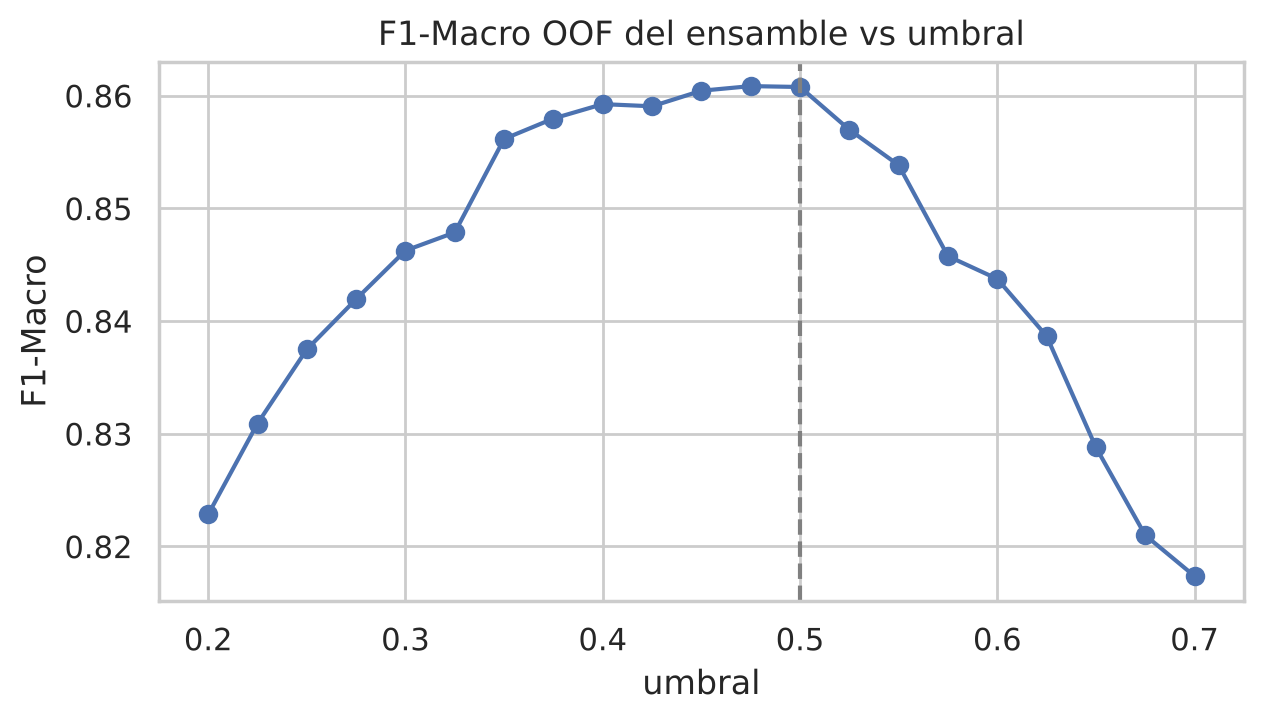

Umbral óptimo OOF: 0.475 -> 0.8609 | umbral 0.5 -> 0.8608
              precision    recall  f1-score   support

           0      0.948     0.969     0.958      4369
           1      0.814     0.719     0.763       828

    accuracy                          0.929      5197
   macro avg      0.881     0.844     0.861      5197
weighted avg      0.926     0.929     0.927      5197



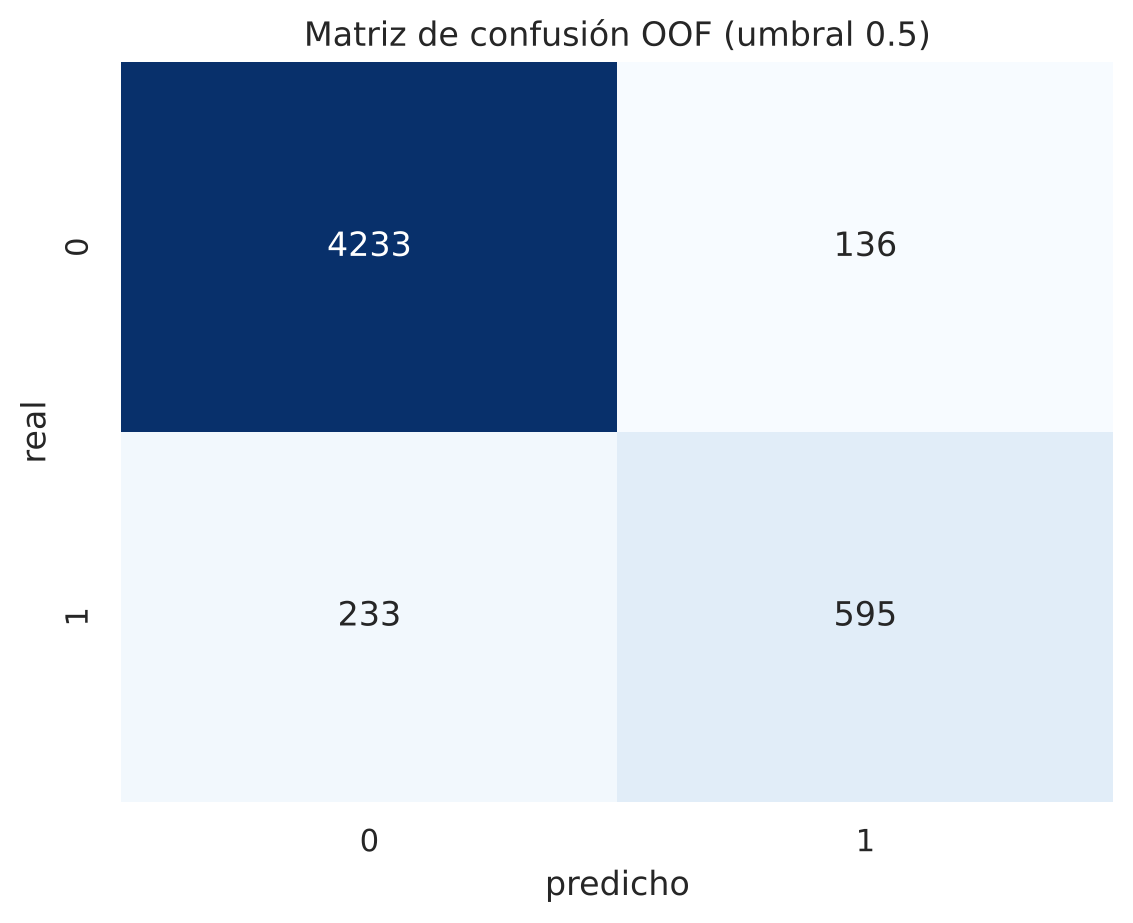

In [17]:
oof = cross_val_predict(ensemble, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
ths = np.arange(0.20, 0.71, 0.025)
f1s = [f1_score(y, (oof >= t).astype(int), average="macro") for t in ths]
plt.figure(figsize=(7, 3.5)); plt.plot(ths, f1s, "o-"); plt.axvline(0.5, ls="--", c="gray")
plt.title("F1-Macro OOF del ensamble vs umbral"); plt.xlabel("umbral"); plt.ylabel("F1-Macro"); plt.show()
print(f"Umbral óptimo OOF: {ths[np.argmax(f1s)]:.3f} -> {max(f1s):.4f} | umbral 0.5 -> {f1_score(y, (oof>=.5).astype(int), average='macro'):.4f}")
print(classification_report(y, (oof >= .5).astype(int), digits=3))
cm = confusion_matrix(y, (oof >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False); plt.title("Matriz de confusión OOF (umbral 0.5)"); plt.xlabel("predicho"); plt.ylabel("real"); plt.show()

La curva es **plana alrededor de 0.5** (el óptimo está a < 0.005 de F1): el umbral por defecto es robusto, así que lo mantenemos en 0.5 y no sobreajustamos el umbral a la validación.

## 7. Tabla comparativa y modelo final

,modelo,familia,f1_macro,f1_std,fit_time_s,pred_time_s
0,ENSAMBLE soft-voting de 3 k-NN (Manhattan + Coseno + FE),Ensamble k-NN,0.8599,0.0077,0.02,0.18
1,"k-NN k=40 Manhattan, peso 1/d",k-NN ponderado,0.8552,0.0092,0.01,0.07
2,"k-NN k=25 Manhattan + FE, peso 1/d",k-NN ponderado,0.8527,0.0115,0.01,0.06
3,"k-NN k=15 Coseno, peso 1/d",k-NN ponderado,0.8517,0.0172,0.01,0.06
4,"MLP (128, 128) tanh α=0.0001",MLP (Red Neuronal),0.8310,0.0205,11.90,0.01
5,"MLP (128, 128) tanh α=0.01",MLP (Red Neuronal),0.8304,0.0197,14.46,0.01
6,"MLP (128, 128) relu α=0.01",MLP (Red Neuronal),0.8208,0.0241,7.55,0.01
7,SVM rbf (mejor del grid),SVM,0.8170,0.0140,0.19,0.04
8,"PCA 95% + SVM RBF (C=3, γ=0.3)",PCA,0.8078,0.0101,0.27,0.07
9,SVM linear (mejor del grid),SVM,0.8068,0.0104,0.24,0.02


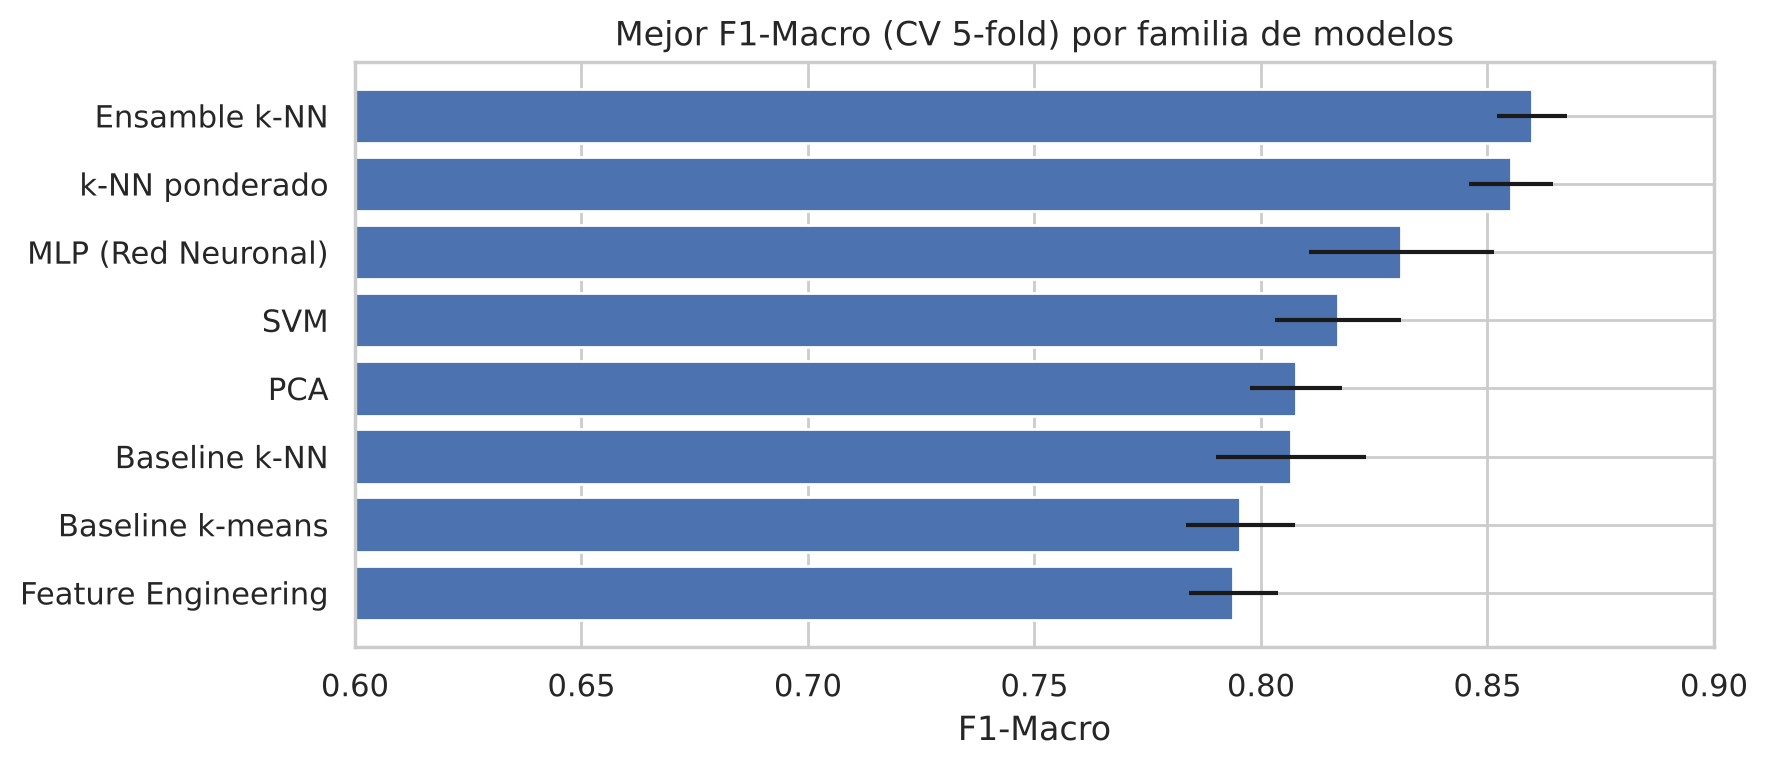

In [18]:
res = (pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True))
res.to_csv(ROOT / "entregas" / "resultados_cv.csv", index=False)
display(res.style.format({"f1_macro": "{:.4f}", "f1_std": "{:.4f}", "fit_time_s": "{:.2f}", "pred_time_s": "{:.2f}"})
          .background_gradient(subset=["f1_macro"], cmap="Greens"))

best_per_family = res.groupby("familia", sort=False).head(1).sort_values("f1_macro")
plt.figure(figsize=(9, 4)); plt.barh(best_per_family["familia"], best_per_family["f1_macro"], xerr=best_per_family["f1_std"], color="C0")
plt.xlim(0.6, 0.9); plt.title("Mejor F1-Macro (CV 5-fold) por familia de modelos"); plt.xlabel("F1-Macro"); plt.tight_layout(); plt.show()

In [19]:
final_model = clone(ensemble).fit(X, y)
pred = final_model.predict(test[BASE_FEATURES])
submission = pd.DataFrame({"id": test["id"], "prediction": pred.astype(int)})
submission.to_csv(ROOT / "entregas" / "submission.csv", index=False)

(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(final_model, ROOT / "models" / "modelo_final.joblib")
joblib.dump(pipe_pca, ROOT / "models" / "pca_pipeline.joblib")

assert submission.shape == (1300, 2) and submission.notna().all().all()
assert (submission["id"].values == test["id"].values).all()
print("submission.csv:", submission.shape, "| % clase 1 predicha:", round(submission.prediction.mean(), 3),
      "| % clase 1 en train:", round(y.mean(), 3))
submission.head()

submission.csv: (1300, 2) | % clase 1 predicha: 0.146 | % clase 1 en train: 0.159


,id,prediction
0,WINE_5797,0
1,WINE_3083,0
2,WINE_3591,0
3,WINE_4648,0
4,WINE_5334,0


## Conclusiones
1. **Escalado obligatorio**: sin él, las distancias y el gradiente quedan dominados por las variables de mayor magnitud.
2. **Baseline** k-NN (k=3,5,7; Euclidiana vs Manhattan) ≈ 0.80–0.81 F1-Macro. k-means por mayoría queda por debajo porque no es supervisado.
3. **Feature engineering**: los ratios fisicoquímicos y el `log1p` ayudan a la MLP (≈0.814 → ≈0.821 en exploración) y al k-NN ponderado de $k$ grande, que es uno de los tres miembros del ensamble final. En k-NN uniforme con k=7 no ayudan (redundancia). Las distancias a centroides k-means suman un poco (+0.005).
4. **PCA** comprime 17 → 9 dimensiones con 95 % de varianza. Ayuda al k-NN con features redundantes, pero no al SVM: útil para visualizar, no entra al modelo final.
5. **SVM RBF** (≈0.817; lineal ≈0.807, polinomial ≈0.790) y **MLP** (≈0.831) superan el baseline uniforme.
6. **El ganador** es un ensamble *soft voting* de 3 k-NN ponderados por $1/d$ (Manhattan, Coseno, Manhattan+FE): **F1-Macro ≈ 0.860 ± 0.008** (el más alto y también el más estable). La estructura local del espacio (muestras repetidas y casi-repetidas) es la señal más fuerte, y la ponderación por distancia la explota sin sobreajustar.